  FLOOD RISK PREDICTION PIPELINE  (User-Knowable Features Only)

[1] Loading dataset ...

    Shape          : 25,000 rows  x  27 columns
    Districts      : ['Colombo', 'Gampaha']
    Flood (Yes/No) : {'Yes': 12506, 'No': 12494}

[2] Preprocessing ...
    Dropped 10 columns (metadata + non-user-knowable)
    Encoded 'district': {'Colombo': np.int64(0), 'Gampaha': np.int64(1)}
    Encoded 'landcover': {'Agriculture': np.int64(0), 'Bare Soil': np.int64(1), 'Forest': np.int64(2), 'Plantation': np.int64(3), 'Scrub': np.int64(4), 'Urban': np.int64(5), 'Wetland': np.int64(6)}
    Encoded 'soil_type': {'Clay': np.int64(0), 'Loamy': np.int64(1), 'Peaty': np.int64(2), 'Sandy': np.int64(3), 'Silty': np.int64(4)}

    Flood label encoding: {'No': np.int64(0), 'Yes': np.int64(1)}

    Final feature columns (12): ['district', 'latitude', 'longitude', 'elevation_m', 'distance_to_river_m', 'landcover', 'soil_type', 'rainfall_7d_mm', 'monthly_rainfall_mm', 'rainfall_intensity_mmhr', 'historical_floo

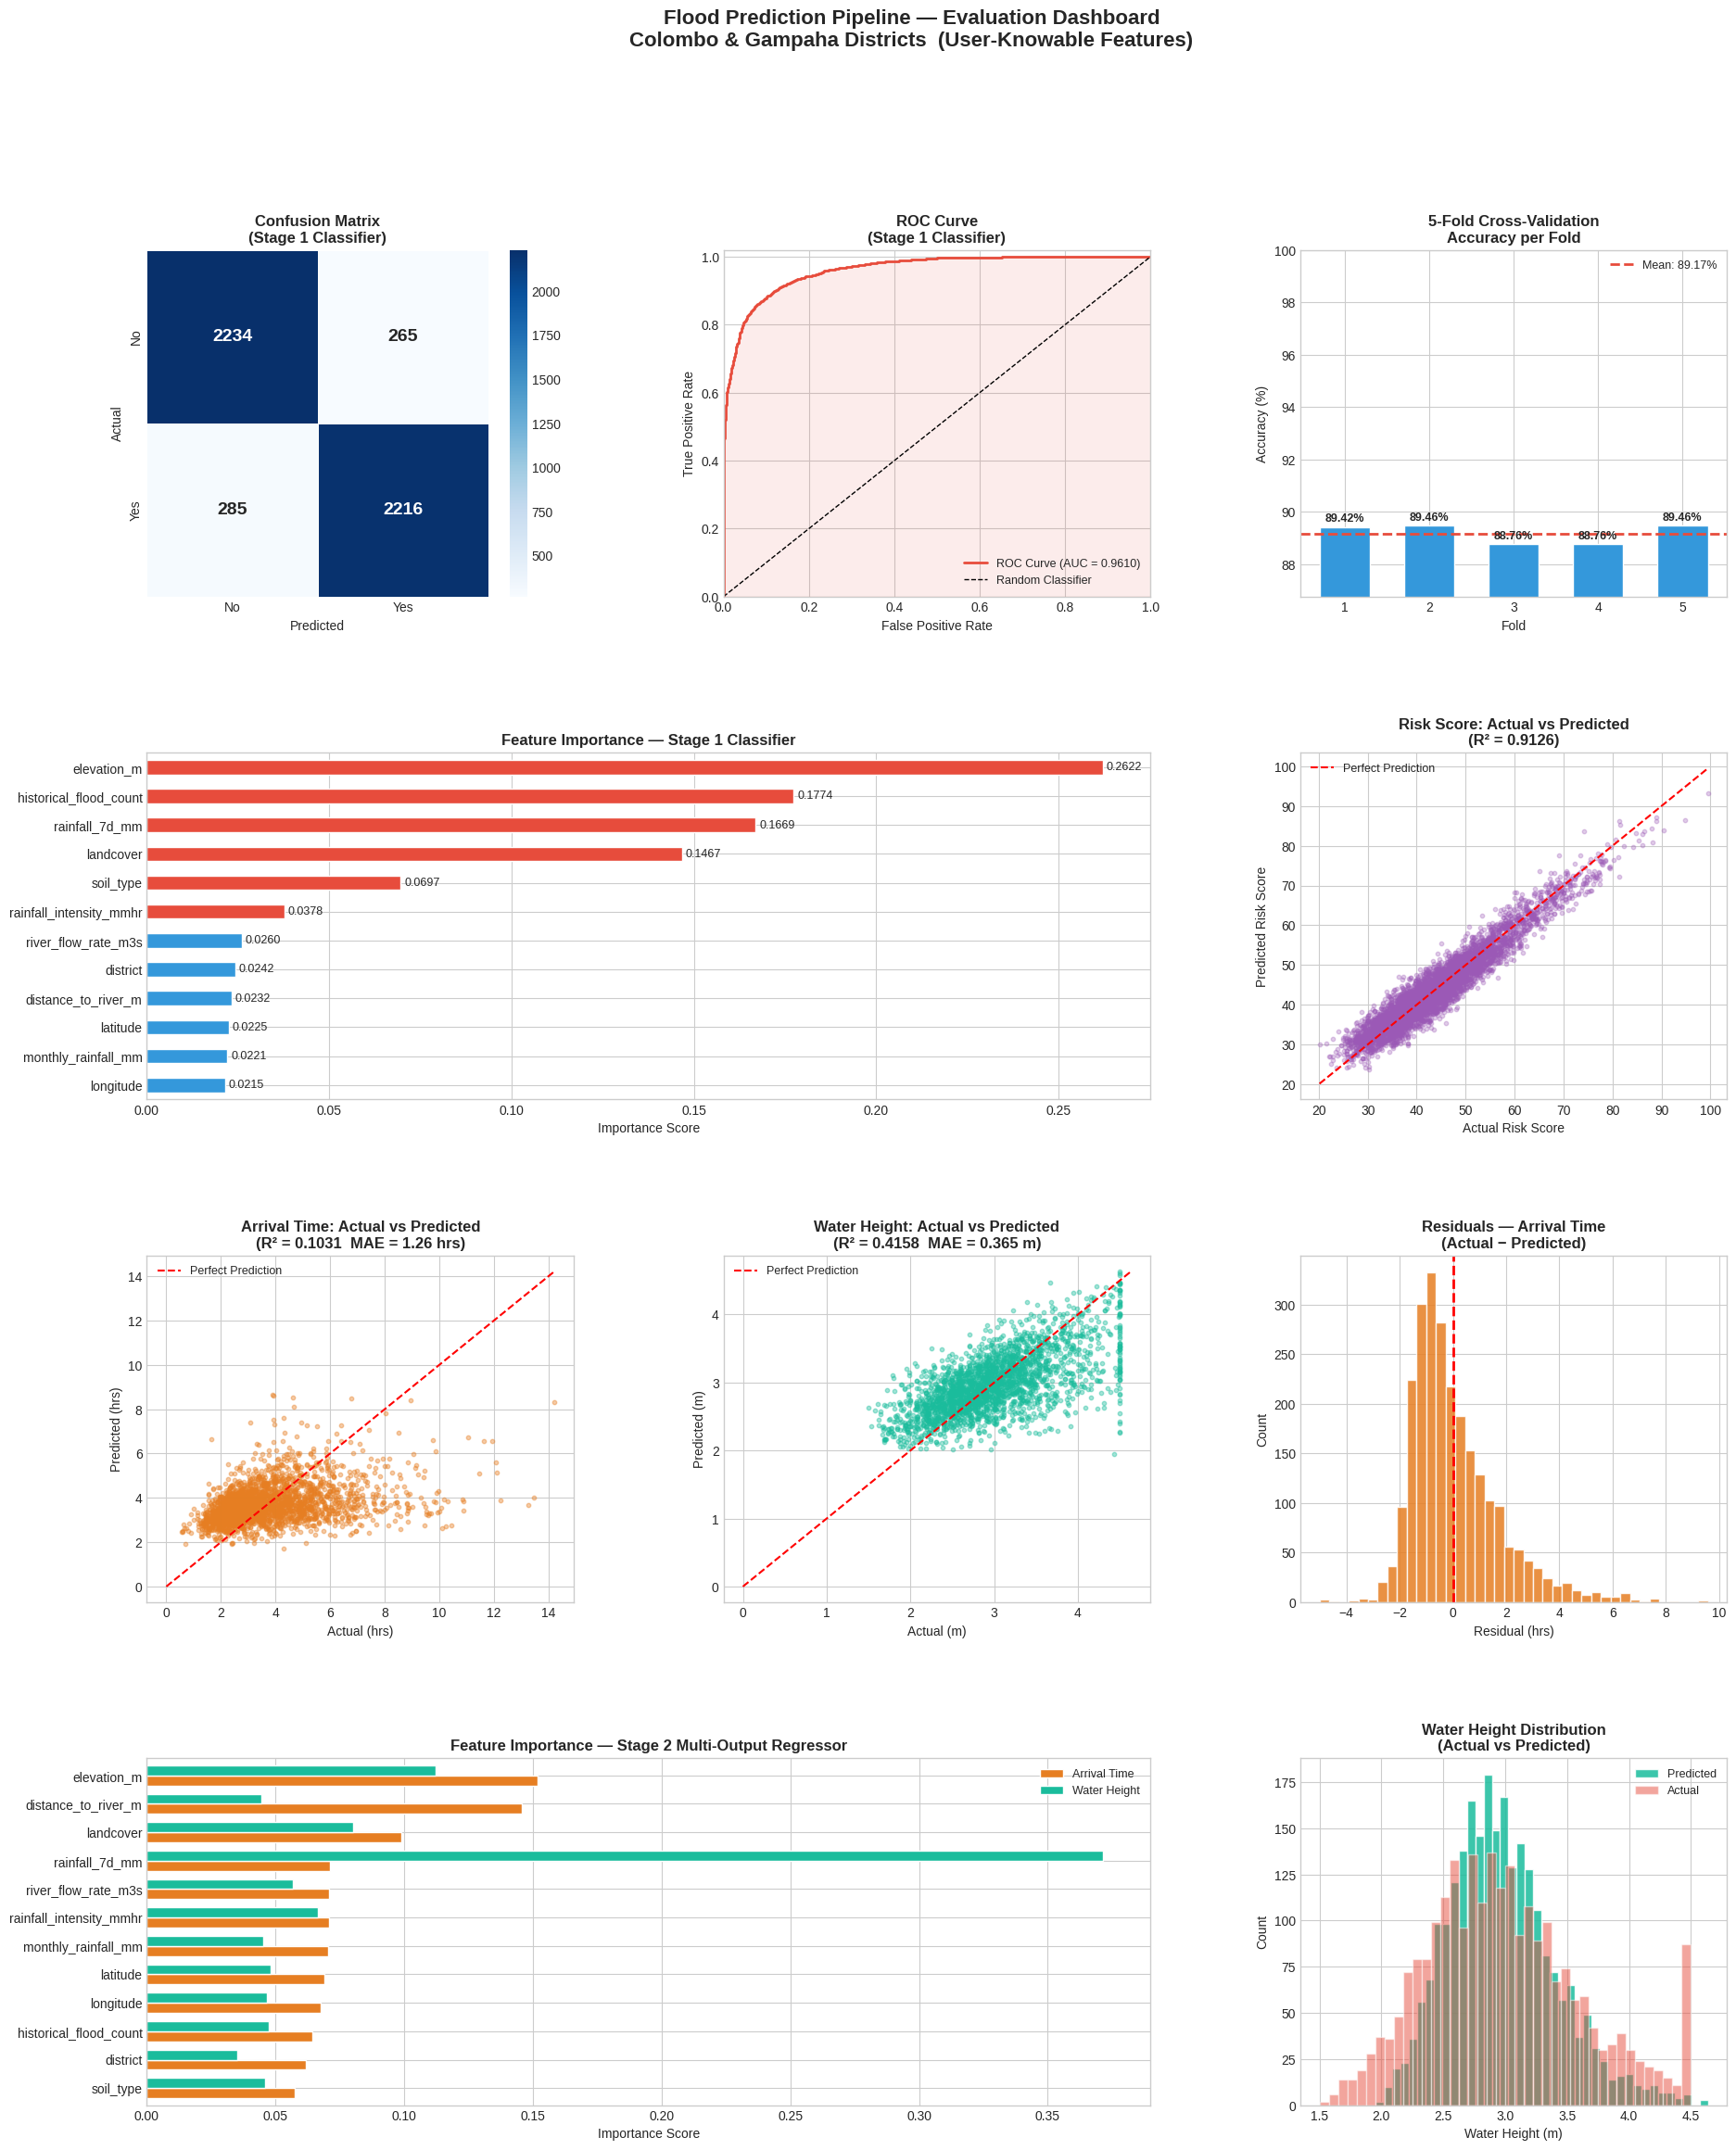

    Plot saved → /kaggle/working/flood_prediction_evaluation.png

[8] Saving models ...
    Saved to /kaggle/working/models/
      ├── stage1_classifier.pkl
      ├── stage1_risk_regressor.pkl
      ├── stage2_multioutput_regressor.pkl
      ├── label_encoders.pkl
      ├── flood_label_encoder.pkl
      └── feature_cols.pkl

[9] Defining prediction function ...

[10] Running example predictions ...

EXAMPLE 1 — High Risk (Colombo, near river, heavy rain):
⚠️  FLOOD RISK DETECTED in Colombo
   Risk Score       : 70.3/100  [Very High]
   Flood Probability: 100.0%
   Arrival Time     : 3h 28m from now
   Expected Height  : 4.42 m
  Full output: {'flood_occurrence': 'Yes', 'flood_probability': 0.9997, 'flood_risk_score': 70.33, 'risk_category': 'Very High', 'arrival_time_hrs': 3.47, 'water_height_m': 4.42, 'summary': '⚠️  FLOOD RISK DETECTED in Colombo\n   Risk Score       : 70.3/100  [Very High]\n   Flood Probability: 100.0%\n   Arrival Time     : 3h 28m from now\n   Expected Height  : 4.

In [1]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║          FLOOD RISK PREDICTION PIPELINE — Colombo & Gampaha Districts       ║
# ║          Stage 1 : Classification  (Will it flood? + Risk Score)            ║
# ║          Stage 2 : Multi-Output Regression (Arrival Time + Water Height)    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# ── 0. Imports ────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, joblib, os
warnings.filterwarnings('ignore')
 
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing   import LabelEncoder
from sklearn.multioutput     import MultiOutputRegressor
from sklearn.metrics         import (accuracy_score, classification_report,
                                     confusion_matrix, roc_auc_score,
                                     mean_absolute_error, mean_squared_error, r2_score)
from sklearn.metrics         import roc_curve
from xgboost import XGBClassifier, XGBRegressor

# ═════════════════════════════════════════════════════════════════════════════
# SECTION 1 — LOAD DATA
# ═════════════════════════════════════════════════════════════════════════════
DATASET_PATH = "/kaggle/input/datasets/bapdesilva/flood-risk-dataset/flood_risk_colombo_gampaha_25000.csv"
 
print("=" * 70)
print("  FLOOD RISK PREDICTION PIPELINE  (User-Knowable Features Only)")
print("=" * 70)
print(f"\n[1] Loading dataset ...\n")
 
df = pd.read_csv(DATASET_PATH)
print(f"    Shape          : {df.shape[0]:,} rows  x  {df.shape[1]} columns")
print(f"    Districts      : {df['district'].unique().tolist()}")
print(f"    Flood (Yes/No) : {df['flood_occurrence_current_event'].value_counts().to_dict()}")

# ═════════════════════════════════════════════════════════════════════════════
# SECTION 2 — PREPROCESSING
# ═════════════════════════════════════════════════════════════════════════════
print("\n[2] Preprocessing ...")
 
# ── Drop metadata + the 8 non-user-knowable columns ──────────────────────────
DROP_COLS = [
    'place_name', 'flood_event_id',          # metadata
    'slope_percent',                          # requires DEM/GIS data
    'dem_elevation_nearest_river_m',          # requires GIS analysis
    'upstream_catchment_area_km2',            # requires hydrological survey
    'built_up_percent',                       # requires satellite imagery
    'ndvi',                                   # requires satellite imagery
    'ndwi',                                   # requires satellite imagery
    'drainage_index',                         # requires engineering survey
    'soil_moisture_percent',                  # requires sensor/lab data
]
df.drop(columns=DROP_COLS, inplace=True)
print(f"    Dropped {len(DROP_COLS)} columns (metadata + non-user-knowable)")
 
# ── Encode categorical features ───────────────────────────────────────────────
CAT_COLS = ['district', 'landcover', 'soil_type']
label_encoders = {}
 
for col in CAT_COLS:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"    Encoded '{col}': {dict(zip(le.classes_, le.transform(le.classes_)))}")
 
# ── Encode target label ───────────────────────────────────────────────────────
flood_le = LabelEncoder()
df['flood_occurrence_encoded'] = flood_le.fit_transform(df['flood_occurrence_current_event'])
print(f"\n    Flood label encoding: {dict(zip(flood_le.classes_, flood_le.transform(flood_le.classes_)))}")
 
# ── Feature columns (12 — all user-knowable) ──────────────────────────────────
FEATURE_COLS = [
    'district',               # which district
    'latitude',               # GPS
    'longitude',              # GPS
    'elevation_m',            # from topographic map / GPS app
    'distance_to_river_m',    # measurable / Google Maps
    'landcover',              # visually observable
    'soil_type',              # local knowledge / basic soil test
    'rainfall_7d_mm',         # weather station / weather app
    'monthly_rainfall_mm',    # weather station / weather app
    'rainfall_intensity_mmhr',# weather station / weather app
    'historical_flood_count', # community knowledge / DMC records
    'river_flow_rate_m3s',    # DMC / irrigation dept gauges
]
 
print(f"\n    Final feature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")

# ═════════════════════════════════════════════════════════════════════════════
# SECTION 3 — SPLIT DATASETS
# ═════════════════════════════════════════════════════════════════════════════
print("\n[3] Splitting datasets ...")
 
X_all  = df[FEATURE_COLS]
y_clf  = df['flood_occurrence_encoded']
y_risk = df['flood_risk_score']
 
# Stage 2: only flood=Yes rows
flood_mask = df['flood_occurrence_current_event'] == 'Yes'
X_flood    = df.loc[flood_mask, FEATURE_COLS]
y_arrival  = df.loc[flood_mask, 'flood_arrival_time_hours']
y_height   = df.loc[flood_mask, 'flood_water_height_m']
y_reg      = pd.concat([y_arrival, y_height], axis=1)
y_reg.columns = ['flood_arrival_time_hours', 'flood_water_height_m']
 
# Train/test splits
X_train_clf, X_test_clf, y_train_clf, y_test_clf, y_train_risk, y_test_risk = \
    train_test_split(X_all, y_clf, y_risk, test_size=0.2, random_state=42, stratify=y_clf)
 
X_train_reg, X_test_reg, y_train_reg, y_test_reg = \
    train_test_split(X_flood, y_reg, test_size=0.2, random_state=42)
 
print(f"    Stage 1 — All rows  : train={len(X_train_clf):,}  test={len(X_test_clf):,}")
print(f"    Stage 2 — Flood rows: train={len(X_train_reg):,}  test={len(X_test_reg):,}")

# ═════════════════════════════════════════════════════════════════════════════
# SECTION 4 — STAGE 1 : CLASSIFIER
# ═════════════════════════════════════════════════════════════════════════════
print("\n[4] Training Stage 1 — XGBoost Classifier ...")
 
clf_model = XGBClassifier(
    n_estimators     = 600,
    max_depth        = 7,
    learning_rate    = 0.04,
    subsample        = 0.85,
    colsample_bytree = 0.85,
    min_child_weight = 3,
    gamma            = 0.1,
    reg_alpha        = 0.1,
    reg_lambda       = 1.5,
    eval_metric      = 'logloss',
    random_state     = 42,
    n_jobs           = -1
)
clf_model.fit(
    X_train_clf, y_train_clf,
    eval_set=[(X_test_clf, y_test_clf)],
    verbose=False
)
 
print("    Training Stage 1 — XGBoost Risk Score Regressor ...")
risk_model = XGBRegressor(
    n_estimators     = 500,
    max_depth        = 6,
    learning_rate    = 0.04,
    subsample        = 0.85,
    colsample_bytree = 0.85,
    random_state     = 42,
    n_jobs           = -1
)
risk_model.fit(X_train_clf, y_train_risk)
 
 
# ═════════════════════════════════════════════════════════════════════════════
# SECTION 5 — STAGE 2 : MULTI-OUTPUT REGRESSOR
# ═════════════════════════════════════════════════════════════════════════════
print("\n[5] Training Stage 2 — Multi-Output XGBoost Regressor ...")
 
reg_model = MultiOutputRegressor(
    XGBRegressor(
        n_estimators     = 600,
        max_depth        = 6,
        learning_rate    = 0.04,
        subsample        = 0.85,
        colsample_bytree = 0.85,
        min_child_weight = 3,
        reg_alpha        = 0.1,
        reg_lambda       = 1.5,
        random_state     = 42,
        n_jobs           = -1
    ),
    n_jobs = -1
)
reg_model.fit(X_train_reg, y_train_reg)
 
 
# ═════════════════════════════════════════════════════════════════════════════
# SECTION 6 — EVALUATION
# ═════════════════════════════════════════════════════════════════════════════
print("\n[6] Evaluating models ...")
print("=" * 70)
 
# ── Stage 1 Classifier ────────────────────────────────────────────────────────
y_pred_clf  = clf_model.predict(X_test_clf)
y_prob_clf  = clf_model.predict_proba(X_test_clf)[:, 1]
clf_accuracy = accuracy_score(y_test_clf, y_pred_clf)
clf_auc      = roc_auc_score(y_test_clf, y_prob_clf)
 
print("\n  ┌─ STAGE 1 : FLOOD OCCURRENCE CLASSIFIER ─────────────────────────┐")
print(f"  │  Accuracy      : {clf_accuracy * 100:.2f}%")
print(f"  │  ROC-AUC       : {clf_auc:.4f}")
print(f"  │\n  │  Classification Report:")
cr = classification_report(y_test_clf, y_pred_clf,
                            target_names=flood_le.classes_, digits=4)
for line in cr.split('\n'):
    print(f"  │  {line}")
 
cv_scores = cross_val_score(clf_model, X_all, y_clf, cv=5, scoring='accuracy', n_jobs=-1)
print(f"  │  5-Fold CV Accuracy : {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%")
print("  └──────────────────────────────────────────────────────────────────┘")
 
# ── Stage 1 Risk Score ────────────────────────────────────────────────────────
y_pred_risk = risk_model.predict(X_test_clf)
risk_mae    = mean_absolute_error(y_test_risk, y_pred_risk)
risk_rmse   = np.sqrt(mean_squared_error(y_test_risk, y_pred_risk))
risk_r2     = r2_score(y_test_risk, y_pred_risk)
 
print("\n  ┌─ STAGE 1 : FLOOD RISK SCORE REGRESSOR ──────────────────────────┐")
print(f"  │  MAE  : {risk_mae:.4f}   RMSE : {risk_rmse:.4f}   R² : {risk_r2:.4f}")
print("  └──────────────────────────────────────────────────────────────────┘")
 
# ── Stage 2 ───────────────────────────────────────────────────────────────────
y_pred_reg = reg_model.predict(X_test_reg)
arr_mae  = mean_absolute_error(y_test_reg['flood_arrival_time_hours'], y_pred_reg[:, 0])
arr_rmse = np.sqrt(mean_squared_error(y_test_reg['flood_arrival_time_hours'], y_pred_reg[:, 0]))
arr_r2   = r2_score(y_test_reg['flood_arrival_time_hours'], y_pred_reg[:, 0])
 
hgt_mae  = mean_absolute_error(y_test_reg['flood_water_height_m'], y_pred_reg[:, 1])
hgt_rmse = np.sqrt(mean_squared_error(y_test_reg['flood_water_height_m'], y_pred_reg[:, 1]))
hgt_r2   = r2_score(y_test_reg['flood_water_height_m'], y_pred_reg[:, 1])
 
print("\n  ┌─ STAGE 2 : FLOOD ARRIVAL TIME (hours) ──────────────────────────┐")
print(f"  │  MAE  : {arr_mae:.4f} hrs   RMSE : {arr_rmse:.4f} hrs   R² : {arr_r2:.4f}")
print("  └──────────────────────────────────────────────────────────────────┘")
 
print("\n  ┌─ STAGE 2 : FLOOD WATER HEIGHT (metres) ─────────────────────────┐")
print(f"  │  MAE  : {hgt_mae:.4f} m   RMSE : {hgt_rmse:.4f} m   R² : {hgt_r2:.4f}")
print("  └──────────────────────────────────────────────────────────────────┘")
 
 
# ═════════════════════════════════════════════════════════════════════════════
# SECTION 7 — VISUALISATIONS
# ═════════════════════════════════════════════════════════════════════════════
print("\n[7] Generating evaluation plots ...")
 
plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'yes': '#E74C3C', 'no': '#2ECC71', 'blue': '#3498DB',
          'orange': '#E67E22', 'purple': '#9B59B6', 'teal': '#1ABC9C'}
 
fig = plt.figure(figsize=(22, 26))
fig.suptitle('Flood Prediction Pipeline — Evaluation Dashboard\nColombo & Gampaha Districts  (User-Knowable Features)',
             fontsize=16, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.45, wspace=0.35)
 
# Plot 1: Confusion Matrix
ax1 = fig.add_subplot(gs[0, 0])
cm  = confusion_matrix(y_test_clf, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=flood_le.classes_,
            yticklabels=flood_le.classes_, ax=ax1,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_title('Confusion Matrix\n(Stage 1 Classifier)', fontweight='bold')
ax1.set_xlabel('Predicted'); ax1.set_ylabel('Actual')
 
# Plot 2: ROC Curve
ax2 = fig.add_subplot(gs[0, 1])
fpr, tpr, _ = roc_curve(y_test_clf, y_prob_clf)
ax2.plot(fpr, tpr, color=COLORS['yes'], lw=2,
         label=f'ROC Curve (AUC = {clf_auc:.4f})')
ax2.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
ax2.fill_between(fpr, tpr, alpha=0.1, color=COLORS['yes'])
ax2.set_title('ROC Curve\n(Stage 1 Classifier)', fontweight='bold')
ax2.set_xlabel('False Positive Rate'); ax2.set_ylabel('True Positive Rate')
ax2.legend(fontsize=9); ax2.set_xlim([0, 1]); ax2.set_ylim([0, 1.02])
 
# Plot 3: 5-Fold CV
ax3 = fig.add_subplot(gs[0, 2])
cv_5fold = cross_val_score(clf_model, X_all, y_clf, cv=5, scoring='accuracy', n_jobs=-1)
bars = ax3.bar(range(1, 6), cv_5fold * 100,
               color=[COLORS['blue']] * 5, edgecolor='white', width=0.6)
ax3.axhline(cv_5fold.mean() * 100, color=COLORS['yes'], lw=2,
            linestyle='--', label=f'Mean: {cv_5fold.mean()*100:.2f}%')
for bar, val in zip(bars, cv_5fold):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{val*100:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax3.set_title('5-Fold Cross-Validation\nAccuracy per Fold', fontweight='bold')
ax3.set_xlabel('Fold'); ax3.set_ylabel('Accuracy (%)')
ax3.set_ylim([min(cv_5fold)*100 - 2, 100]); ax3.legend(fontsize=9)
 
# Plot 4: Feature Importance — Classifier
ax4 = fig.add_subplot(gs[1, :2])
fi_clf    = pd.Series(clf_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
colors_fi = [COLORS['yes'] if v > fi_clf.median() else COLORS['blue'] for v in fi_clf]
fi_clf.plot(kind='barh', ax=ax4, color=colors_fi, edgecolor='white')
ax4.set_title('Feature Importance — Stage 1 Classifier', fontweight='bold')
ax4.set_xlabel('Importance Score')
for i, (val, name) in enumerate(zip(fi_clf.values, fi_clf.index)):
    ax4.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=9)
 
# Plot 5: Risk Score Actual vs Predicted
ax5 = fig.add_subplot(gs[1, 2])
ax5.scatter(y_test_risk, y_pred_risk, alpha=0.3, s=10, color=COLORS['purple'])
lims = [min(y_test_risk.min(), y_pred_risk.min()),
        max(y_test_risk.max(), y_pred_risk.max())]
ax5.plot(lims, lims, 'r--', lw=1.5, label='Perfect Prediction')
ax5.set_title(f'Risk Score: Actual vs Predicted\n(R² = {risk_r2:.4f})', fontweight='bold')
ax5.set_xlabel('Actual Risk Score'); ax5.set_ylabel('Predicted Risk Score')
ax5.legend(fontsize=9)
 
# Plot 6: Arrival Time Actual vs Predicted
ax6 = fig.add_subplot(gs[2, 0])
ax6.scatter(y_test_reg['flood_arrival_time_hours'], y_pred_reg[:, 0],
            alpha=0.4, s=10, color=COLORS['orange'])
lims6 = [0, max(y_test_reg['flood_arrival_time_hours'].max(), y_pred_reg[:, 0].max())]
ax6.plot(lims6, lims6, 'r--', lw=1.5, label='Perfect Prediction')
ax6.set_title(f'Arrival Time: Actual vs Predicted\n(R² = {arr_r2:.4f}  MAE = {arr_mae:.2f} hrs)',
              fontweight='bold')
ax6.set_xlabel('Actual (hrs)'); ax6.set_ylabel('Predicted (hrs)')
ax6.legend(fontsize=9)
 
# Plot 7: Water Height Actual vs Predicted
ax7 = fig.add_subplot(gs[2, 1])
ax7.scatter(y_test_reg['flood_water_height_m'], y_pred_reg[:, 1],
            alpha=0.4, s=10, color=COLORS['teal'])
lims7 = [0, max(y_test_reg['flood_water_height_m'].max(), y_pred_reg[:, 1].max())]
ax7.plot(lims7, lims7, 'r--', lw=1.5, label='Perfect Prediction')
ax7.set_title(f'Water Height: Actual vs Predicted\n(R² = {hgt_r2:.4f}  MAE = {hgt_mae:.3f} m)',
              fontweight='bold')
ax7.set_xlabel('Actual (m)'); ax7.set_ylabel('Predicted (m)')
ax7.legend(fontsize=9)
 
# Plot 8: Residuals — Arrival Time
ax8 = fig.add_subplot(gs[2, 2])
arr_residuals = y_test_reg['flood_arrival_time_hours'].values - y_pred_reg[:, 0]
ax8.hist(arr_residuals, bins=40, color=COLORS['orange'], edgecolor='white', alpha=0.85)
ax8.axvline(0, color='red', lw=2, linestyle='--')
ax8.set_title('Residuals — Arrival Time\n(Actual − Predicted)', fontweight='bold')
ax8.set_xlabel('Residual (hrs)'); ax8.set_ylabel('Count')
 
# Plot 9: Feature Importance — Stage 2
ax9 = fig.add_subplot(gs[3, :2])
fi_arr = pd.Series(reg_model.estimators_[0].feature_importances_, index=FEATURE_COLS)
fi_hgt = pd.Series(reg_model.estimators_[1].feature_importances_, index=FEATURE_COLS)
fi_reg = pd.DataFrame({'Arrival Time': fi_arr, 'Water Height': fi_hgt})
fi_reg.sort_values('Arrival Time', ascending=True).plot(
    kind='barh', ax=ax9,
    color=[COLORS['orange'], COLORS['teal']],
    edgecolor='white', width=0.7
)
ax9.set_title('Feature Importance — Stage 2 Multi-Output Regressor', fontweight='bold')
ax9.set_xlabel('Importance Score'); ax9.legend(fontsize=9)
 
# Plot 10: Water Height Distribution
ax10 = fig.add_subplot(gs[3, 2])
ax10.hist(y_pred_reg[:, 1], bins=40, color=COLORS['teal'],
          edgecolor='white', alpha=0.85, label='Predicted')
ax10.hist(y_test_reg['flood_water_height_m'], bins=40, color=COLORS['yes'],
          edgecolor='white', alpha=0.5, label='Actual')
ax10.set_title('Water Height Distribution\n(Actual vs Predicted)', fontweight='bold')
ax10.set_xlabel('Water Height (m)'); ax10.set_ylabel('Count')
ax10.legend(fontsize=9)
 
plt.savefig('/kaggle/working/flood_prediction_evaluation.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("    Plot saved → /kaggle/working/flood_prediction_evaluation.png")
 
 
# ═════════════════════════════════════════════════════════════════════════════
# SECTION 8 — SAVE MODELS
# ═════════════════════════════════════════════════════════════════════════════
print("\n[8] Saving models ...")
os.makedirs('/kaggle/working/models', exist_ok=True)
 
joblib.dump(clf_model,      '/kaggle/working/models/stage1_classifier.pkl')
joblib.dump(risk_model,     '/kaggle/working/models/stage1_risk_regressor.pkl')
joblib.dump(reg_model,      '/kaggle/working/models/stage2_multioutput_regressor.pkl')
joblib.dump(label_encoders, '/kaggle/working/models/label_encoders.pkl')
joblib.dump(flood_le,       '/kaggle/working/models/flood_label_encoder.pkl')
joblib.dump(FEATURE_COLS,   '/kaggle/working/models/feature_cols.pkl')
 
print("    Saved to /kaggle/working/models/")
print("      ├── stage1_classifier.pkl")
print("      ├── stage1_risk_regressor.pkl")
print("      ├── stage2_multioutput_regressor.pkl")
print("      ├── label_encoders.pkl")
print("      ├── flood_label_encoder.pkl")
print("      └── feature_cols.pkl")
 
 
# ═════════════════════════════════════════════════════════════════════════════
# SECTION 9 — PREDICTION FUNCTION
# ═════════════════════════════════════════════════════════════════════════════
print("\n[9] Defining prediction function ...")
 
def predict_flood(
    district,               # str   : 'Colombo' or 'Gampaha'
    latitude,               # float : GPS latitude  e.g. 6.9271
    longitude,              # float : GPS longitude e.g. 79.8612
    elevation_m,            # float : metres above sea level (topographic map / GPS)
    distance_to_river_m,    # float : distance to nearest river in metres (Google Maps)
    landcover,              # str   : 'Urban','Agriculture','Wetland','Forest','Plantation','Scrub','Bare Soil'
    soil_type,              # str   : 'Clay','Peaty','Silty','Loamy','Sandy'
    rainfall_7d_mm,         # float : total rainfall last 7 days mm (weather app / station)
    monthly_rainfall_mm,    # float : total rainfall this month mm  (weather app / station)
    rainfall_intensity_mmhr,# float : peak rainfall rate mm/hr      (weather app / station)
    historical_flood_count, # int   : past floods at this location  (DMC records / community)
    river_flow_rate_m3s,    # float : current river discharge m³/s  (DMC / irrigation dept)
    flood_threshold_prob=0.50
):
    """
    Predicts flood risk for a given location using only user-knowable inputs.
 
    Returns dict:
        flood_occurrence   : 'Yes' or 'No'
        flood_probability  : 0.0–1.0
        flood_risk_score   : 0–100
        risk_category      : 'Low' / 'Moderate' / 'High' / 'Very High'
        arrival_time_hrs   : hours until water arrives  (None if no flood)
        water_height_m     : expected water height in m (None if no flood)
        summary            : human-readable result string
    """
    district_enc  = label_encoders['district'].transform([district])[0]
    landcover_enc = label_encoders['landcover'].transform([landcover])[0]
    soil_enc      = label_encoders['soil_type'].transform([soil_type])[0]
 
    features = pd.DataFrame([[
        district_enc, latitude, longitude, elevation_m, distance_to_river_m,
        landcover_enc, soil_enc, rainfall_7d_mm, monthly_rainfall_mm,
        rainfall_intensity_mmhr, historical_flood_count, river_flow_rate_m3s
    ]], columns=FEATURE_COLS)
 
    # Stage 1
    flood_prob   = clf_model.predict_proba(features)[0][1]
    flood_occurs = 'Yes' if flood_prob >= flood_threshold_prob else 'No'
    risk_score   = float(np.clip(risk_model.predict(features)[0], 0, 100))
 
    if   risk_score >= 70: risk_cat = 'Very High'
    elif risk_score >= 50: risk_cat = 'High'
    elif risk_score >= 30: risk_cat = 'Moderate'
    else:                  risk_cat = 'Low'
 
    # Stage 2
    arrival_time = water_height = None
    if flood_occurs == 'Yes':
        reg_pred     = reg_model.predict(features)[0]
        arrival_time = float(np.clip(reg_pred[0], 0.1, 200))
        water_height = float(np.clip(reg_pred[1], 0.0, 10.0))
 
    if flood_occurs == 'Yes':
        hrs     = int(arrival_time)
        mins    = int((arrival_time - hrs) * 60)
        summary = (
            f"⚠️  FLOOD RISK DETECTED in {district}\n"
            f"   Risk Score       : {risk_score:.1f}/100  [{risk_cat}]\n"
            f"   Flood Probability: {flood_prob*100:.1f}%\n"
            f"   Arrival Time     : {hrs}h {mins}m from now\n"
            f"   Expected Height  : {water_height:.2f} m"
        )
    else:
        summary = (
            f"✅  NO FLOOD RISK DETECTED in {district}\n"
            f"   Risk Score       : {risk_score:.1f}/100  [{risk_cat}]\n"
            f"   Flood Probability: {flood_prob*100:.1f}%\n"
            f"   Arrival Time     : N/A\n"
            f"   Expected Height  : N/A"
        )
 
    return {
        'flood_occurrence' : flood_occurs,
        'flood_probability': round(float(flood_prob), 4),
        'flood_risk_score' : round(risk_score, 2),
        'risk_category'    : risk_cat,
        'arrival_time_hrs' : round(arrival_time, 2) if arrival_time else None,
        'water_height_m'   : round(water_height, 2) if water_height else None,
        'summary'          : summary
    }
 
 
# ═════════════════════════════════════════════════════════════════════════════
# SECTION 10 — EXAMPLE PREDICTIONS
# ═════════════════════════════════════════════════════════════════════════════
print("\n[10] Running example predictions ...\n")
print("=" * 70)
 
# Example 1 — High risk
r1 = predict_flood(
    district='Colombo', latitude=6.9271, longitude=79.8612,
    elevation_m=2, distance_to_river_m=120,
    landcover='Urban', soil_type='Clay',
    rainfall_7d_mm=210.0, monthly_rainfall_mm=380.0,
    rainfall_intensity_mmhr=28.5, historical_flood_count=4,
    river_flow_rate_m3s=420.0
)
print("EXAMPLE 1 — High Risk (Colombo, near river, heavy rain):")
print(r1['summary'])
print(f"  Full output: {r1}\n")
print("-" * 70)
 
# Example 2 — Low risk
r2 = predict_flood(
    district='Gampaha', latitude=7.1500, longitude=80.0800,
    elevation_m=45, distance_to_river_m=3500,
    landcover='Agriculture', soil_type='Sandy',
    rainfall_7d_mm=18.0, monthly_rainfall_mm=55.0,
    rainfall_intensity_mmhr=2.1, historical_flood_count=0,
    river_flow_rate_m3s=35.0
)
print("\nEXAMPLE 2 — Low Risk (Gampaha, elevated, dry):")
print(r2['summary'])
print(f"  Full output: {r2}\n")
print("-" * 70)
 
# Example 3 — Moderate risk
r3 = predict_flood(
    district='Colombo', latitude=6.8750, longitude=79.9200,
    elevation_m=12, distance_to_river_m=850,
    landcover='Wetland', soil_type='Peaty',
    rainfall_7d_mm=95.0, monthly_rainfall_mm=180.0,
    rainfall_intensity_mmhr=12.0, historical_flood_count=2,
    river_flow_rate_m3s=145.0
)
print("\nEXAMPLE 3 — Moderate Risk (Colombo, wetland, moderate rain):")
print(r3['summary'])
print(f"  Full output: {r3}\n")
print("=" * 70)
 
# ── Final scorecard ───────────────────────────────────────────────────────────
print("\n╔══════════════════════════════════════════════════════════════════════╗")
print("║                     FINAL MODEL SCORECARD                          ║")
print("╠══════════════════════════════════════════════════════════════════════╣")
print(f"║  Stage 1 — Classifier                                              ║")
print(f"║    Accuracy           : {clf_accuracy*100:>6.2f}%                                   ║")
print(f"║    ROC-AUC            : {clf_auc:>6.4f}                                    ║")
print(f"║    5-Fold CV Accuracy : {cv_scores.mean()*100:>6.2f}% ± {cv_scores.std()*100:.2f}%                     ║")
print(f"║                                                                    ║")
print(f"║  Stage 1 — Risk Score Regressor    R² : {risk_r2:>6.4f}  MAE : {risk_mae:>6.4f}   ║")
print(f"║  Stage 2 — Arrival Time Regressor  R² : {arr_r2:>6.4f}  MAE : {arr_mae:>5.2f} hrs  ║")
print(f"║  Stage 2 — Water Height Regressor  R² : {hgt_r2:>6.4f}  MAE : {hgt_mae:>6.4f} m   ║")
print("╚══════════════════════════════════════════════════════════════════════╝")
print("\nAll models saved to /kaggle/working/models/")

In [3]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║              INTERACTIVE FLOOD RISK PREDICTION — TEST CELL                 ║
# ║  Loads saved models and accepts text inputs from the user to make          ║
# ║  live predictions (flood occurrence, risk score, arrival time, height)     ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

import joblib
import numpy as np
import pandas as pd
import os

# ─────────────────────────────────────────────────────────────────────────────
# STEP 1 — Load saved models & encoders
# ─────────────────────────────────────────────────────────────────────────────
MODEL_DIR = "/kaggle/working/models"

print("=" * 70)
print("  FLOOD RISK PREDICTION — INTERACTIVE TEST")
print("=" * 70)
print(f"\nLoading models from: {MODEL_DIR}\n")

clf_model      = joblib.load(os.path.join(MODEL_DIR, "stage1_classifier.pkl"))
risk_model     = joblib.load(os.path.join(MODEL_DIR, "stage1_risk_regressor.pkl"))
reg_model      = joblib.load(os.path.join(MODEL_DIR, "stage2_multioutput_regressor.pkl"))
label_encoders = joblib.load(os.path.join(MODEL_DIR, "label_encoders.pkl"))
flood_le       = joblib.load(os.path.join(MODEL_DIR, "flood_label_encoder.pkl"))
FEATURE_COLS   = joblib.load(os.path.join(MODEL_DIR, "feature_cols.pkl"))

print("  ✅  All models loaded successfully.")
print(f"  ✅  Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")

# ─────────────────────────────────────────────────────────────────────────────
# STEP 2 — Helper utilities
# ─────────────────────────────────────────────────────────────────────────────

def encode_categorical(col, value):
    """Encode a categorical value; warn and fall back to 0 if unseen."""
    le = label_encoders[col]
    if value in le.classes_:
        return le.transform([value])[0]
    print(f"  ⚠️  Unknown '{value}' for '{col}'. Valid: {list(le.classes_)}. Using 0.")
    return 0

def get_float(prompt, default):
    """Prompt for a float; return default on empty or invalid input."""
    raw = input(f"  {prompt} [default={default}]: ").strip()
    if raw == "":
        return default
    try:
        return float(raw)
    except ValueError:
        print(f"  ⚠️  Invalid — using default ({default}).")
        return default

def get_str(prompt, options, default):
    """Prompt for a string choice; return default on empty input."""
    raw = input(f"  {prompt} {options} [default={default}]: ").strip()
    return raw if raw else default

# ─────────────────────────────────────────────────────────────────────────────
# STEP 3 — Core prediction function
# ─────────────────────────────────────────────────────────────────────────────

def predict(input_dict):
    """
    Run the two-stage pipeline on a single input dict.

    Returns dict with keys:
        flood_occurrence, flood_probability, flood_risk_score,
        risk_category, arrival_time_hrs, water_height_m, summary
    """
    row = input_dict.copy()
    for col in ['district', 'landcover', 'soil_type']:
        row[col] = encode_categorical(col, row[col])

    X = pd.DataFrame([row])[FEATURE_COLS]

    # ── Stage 1: flood classification + risk score ────────────────────────────
    flood_prob  = clf_model.predict_proba(X)[0][1]
    flood_pred  = clf_model.predict(X)[0]
    flood_label = flood_le.inverse_transform([flood_pred])[0]
    risk_score  = float(np.clip(risk_model.predict(X)[0], 0, 100))

    if   risk_score >= 70: risk_cat = "Very High"
    elif risk_score >= 50: risk_cat = "High"
    elif risk_score >= 30: risk_cat = "Moderate"
    else:                  risk_cat = "Low"

    # ── Stage 2: arrival time + water height (flood rows only) ────────────────
    arrival_hrs  = None
    water_height = None

    if flood_pred == 1:
        reg_pred     = reg_model.predict(X)[0]
        arrival_hrs  = round(float(np.clip(reg_pred[0], 0.1, 200)), 2)
        water_height = round(float(np.clip(reg_pred[1], 0.0, 10.0)), 2)

    # ── Summary string ────────────────────────────────────────────────────────
    district_name = input_dict['district']

    if flood_pred == 1:
        h = int(arrival_hrs)
        m = int(round((arrival_hrs - h) * 60))
        summary = (
            f"⚠️  FLOOD RISK DETECTED in {district_name}\n"
            f"   Risk Score       : {risk_score:.1f}/100  [{risk_cat}]\n"
            f"   Flood Probability: {flood_prob*100:.1f}%\n"
            f"   Arrival Time     : {h}h {m:02d}m from now\n"
            f"   Expected Height  : {water_height:.2f} m"
        )
    else:
        summary = (
            f"✅  NO FLOOD RISK DETECTED in {district_name}\n"
            f"   Risk Score       : {risk_score:.1f}/100  [{risk_cat}]\n"
            f"   Flood Probability: {flood_prob*100:.1f}%\n"
            f"   Arrival Time     : N/A\n"
            f"   Expected Height  : N/A"
        )

    return {
        "flood_occurrence"  : flood_label,
        "flood_probability" : round(float(flood_prob), 4),
        "flood_risk_score"  : round(risk_score, 2),
        "risk_category"     : risk_cat,
        "arrival_time_hrs"  : arrival_hrs,
        "water_height_m"    : water_height,
        "summary"           : summary,
    }

# ─────────────────────────────────────────────────────────────────────────────
# STEP 4 — Interactive input loop
# ─────────────────────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("  Enter location & weather details below.")
print("  Press ENTER on any field to accept the default value.")
print("=" * 70)

district_opts  = list(label_encoders['district'].classes_)
landcover_opts = list(label_encoders['landcover'].classes_)
soil_opts      = list(label_encoders['soil_type'].classes_)

while True:
    print()
    print("  ── Location ──────────────────────────────────────────────────────")

    district  = get_str("District",   district_opts,  "Colombo")
    latitude  = get_float("Latitude  (°N)",             6.92)
    longitude = get_float("Longitude (°E)",            79.85)
    elevation_m         = get_float("Elevation (m above sea level)",  5.0)
    distance_to_river_m = get_float("Distance to nearest river (m)", 150.0)

    print("\n  ── Land & Soil ───────────────────────────────────────────────────")

    landcover = get_str("Land cover", landcover_opts, "Urban")
    soil_type = get_str("Soil type",  soil_opts,      "Clay")

    print("\n  ── Rainfall & Hydrology ──────────────────────────────────────────")

    rainfall_7d_mm           = get_float("Rainfall last 7 days (mm)",      200.0)
    monthly_rainfall_mm      = get_float("Monthly rainfall (mm)",           350.0)
    rainfall_intensity_mmhr  = get_float("Rainfall intensity (mm/hr)",       15.0)
    river_flow_rate_m3s      = get_float("River flow rate (m³/s)",          120.0)

    print("\n  ── History ───────────────────────────────────────────────────────")

    historical_flood_count = get_float("Past flood events at this location", 2.0)

    # ── Assemble & predict ────────────────────────────────────────────────────
    user_input = {
        "district"              : district,
        "latitude"              : latitude,
        "longitude"             : longitude,
        "elevation_m"           : elevation_m,
        "distance_to_river_m"   : distance_to_river_m,
        "landcover"             : landcover,
        "soil_type"             : soil_type,
        "rainfall_7d_mm"        : rainfall_7d_mm,
        "monthly_rainfall_mm"   : monthly_rainfall_mm,
        "rainfall_intensity_mmhr": rainfall_intensity_mmhr,
        "historical_flood_count": historical_flood_count,
        "river_flow_rate_m3s"   : river_flow_rate_m3s,
    }

    print("\n" + "-" * 70)
    print("  PREDICTION RESULT:")
    print("-" * 70)

    result = predict(user_input)
    print(result["summary"])

    print("\n  Full result:")
    for k, v in result.items():
        if k != "summary":
            print(f"    {k:<26}: {v}")

    print("\n" + "=" * 70)

    again = input("\n  Run another prediction? (y/n) [default=y]: ").strip().lower()
    if again == "n":
        print("\n  Goodbye! 👋")
        break

  FLOOD RISK PREDICTION — INTERACTIVE TEST

Loading models from: /kaggle/working/models

  ✅  All models loaded successfully.
  ✅  Features (12): ['district', 'latitude', 'longitude', 'elevation_m', 'distance_to_river_m', 'landcover', 'soil_type', 'rainfall_7d_mm', 'monthly_rainfall_mm', 'rainfall_intensity_mmhr', 'historical_flood_count', 'river_flow_rate_m3s']

  Enter location & weather details below.
  Press ENTER on any field to accept the default value.

  ── Location ──────────────────────────────────────────────────────


  District ['Colombo', 'Gampaha'] [default=Colombo]:  Colombo
  Latitude  (°N) [default=6.92]:  6.936489
  Longitude (°E) [default=79.85]:  79.983391
  Elevation (m above sea level) [default=5.0]:  15
  Distance to nearest river (m) [default=150.0]:  500



  ── Land & Soil ───────────────────────────────────────────────────


  Land cover ['Agriculture', 'Bare Soil', 'Forest', 'Plantation', 'Scrub', 'Urban', 'Wetland'] [default=Urban]:  Urban
  Soil type ['Clay', 'Loamy', 'Peaty', 'Sandy', 'Silty'] [default=Clay]:  Clay



  ── Rainfall & Hydrology ──────────────────────────────────────────


...


  ── History ───────────────────────────────────────────────────────


  Past flood events at this location [default=2.0]:  6



----------------------------------------------------------------------
  PREDICTION RESULT:
----------------------------------------------------------------------
⚠️  FLOOD RISK DETECTED in Colombo
   Risk Score       : 63.4/100  [High]
   Flood Probability: 100.0%
   Arrival Time     : 4h 20m from now
   Expected Height  : 4.20 m

  Full result:
    flood_occurrence          : Yes
    flood_probability         : 0.9999
    flood_risk_score          : 63.38
    risk_category             : High
    arrival_time_hrs          : 4.33
    water_height_m            : 4.2




  Run another prediction? (y/n) [default=y]:  n



  Goodbye! 👋
